In [1]:
import json
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from time import time
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sentence_transformers import SentenceTransformer
from collections import Counter
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder


c:\Users\User\CityActivities\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
current_dir = os.getcwd()
parent_dir = os.path.dirname(current_dir)

DATA_PATH = os.path.join(parent_dir, 'data', 'synthetic_dataset.json')
with open(DATA_PATH, 'r', encoding='utf-8') as f:
    data = json.load(f)
df = pd.DataFrame(data)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 529 entries, 0 to 528
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   text           529 non-null    str  
 1   event_type     529 non-null    str  
 2   address        437 non-null    str  
 3   is_actionable  529 non-null    bool 
 4   is_planned     529 non-null    bool 
dtypes: bool(2), str(3)
memory usage: 13.6 KB


# classifier

In [3]:
MODEL_NAME = "paraphrase-multilingual-mpnet-base-v2"
model = SentenceTransformer(MODEL_NAME)

X = model.encode(df['text'], show_progress_bar=True, batch_size=32)
y = np.array(df['event_type'])

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1461.31it/s]
XLMRobertaModel LOAD REPORT from: sentence-transformers/paraphrase-multilingual-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Batches: 100%|██████████| 17/17 [00:56<00:00,  3.31s/it]


In [ ]:
X.shape, y.shape

In [4]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y) 

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print(f"Train: {len(X_train)} ({len(X_train)/len(X):.1%})")
print(f"Test:  {len(X_test)}  ({len(X_test)/len(X):.1%})")


Train: 423 (80.0%)
Test:  106  (20.0%)


In [5]:
models = {
    "Logistic Regression": {
        "model": LogisticRegression(max_iter=1000, random_state=42),
        "params": {
            'C': [0.1, 1, 5, 10, 50],
            'solver': ['lbfgs', 'newton-cg', 'sag'],
            'class_weight': [None, 'balanced']
        }
    },
    
    "SVM (Linear)": {
        "model": SVC(kernel="linear", random_state=42, probability=True),
        "params": {
            'C': [0.1, 1, 5, 10],
            'class_weight': [None, 'balanced']
        }
    },
    
    "SVM (RBF)": {
        "model": SVC(kernel="rbf", random_state=42, probability=True),
        "params": {
            'C': [1, 5, 10, 50],
            'gamma': ['scale', 'auto', 0.001, 0.01],
            'class_weight': [None, 'balanced']
        }
    },
    
    "Random Forest": {
        "model": RandomForestClassifier(random_state=42),
        "params": {
            'n_estimators': [100, 200, 300],
            'max_depth': [None, 15, 25],
            'class_weight': [None, 'balanced', 'balanced_subsample']
        }
    },
    
    "XGBoost": {
        "model": XGBClassifier(random_state=42, eval_metric='mlogloss'),
        "params": {
            'n_estimators': [100, 200],
            'max_depth': [3, 5, 7],
            'learning_rate': [0.05, 0.1, 0.2],
            'subsample': [0.8, 1.0]
        }
    }
}

results = {}
best_model = None
best_score = -1
best_name = ""

for name, config in models.items():
    print(f"====={name}=====")
    start_time = time()
    
    search = RandomizedSearchCV(
        estimator=config["model"],
        param_distributions=config["params"],
        n_iter=8,                   
        scoring='f1_macro',         
        cv=5,                         
        n_jobs=-1,              
        random_state=42,
        verbose=0
    )
    
    search.fit(X_train, y_train)
    
    best_clf = search.best_estimator_
    y_pred = best_clf.predict(X_test)
    
    results[name] = {
        "clf": best_clf,
        "best_params": search.best_params_,
        "best_cv_score": search.best_score_,
        "y_pred": y_pred,
        "f1_macro": f1_score(y_test, y_pred, average='macro'),
        "accuracy": accuracy_score(y_test, y_pred)
    }
    
    print(f"Best params: {search.best_params_}")
    print(f"CV F1-macro: {search.best_score_:.4f}")
    print(f"Test  F1-macro: {results[name]['f1_macro']:.4f}")
    print(f"Accuracy: {results[name]['accuracy']:.4f}")
    print(f"Time: {time() - start_time:.1f} sec")
    
    if results[name]['f1_macro'] > best_score:
        best_score = results[name]['f1_macro']
        best_model = best_clf
        best_name = name


print(f"Best model: {best_name} (F1-macro = {best_score:.4f})")
print("\nDetailed classification report for the best model:")
print(classification_report(y_test, best_model.predict(X_test), zero_division=0))

#import joblib
#joblib.dump(best_model, f'best_model_{best_name.replace(" ", "_")}.pkl')
#print(f"\nBest model saved as: best_model_{best_name.replace(' ', '_')}.pkl")

=====Logistic Regression=====
Best params: {'solver': 'lbfgs', 'class_weight': None, 'C': 50}
CV F1-macro: 0.8973
Test  F1-macro: 0.9445
Accuracy: 0.9434
Time: 30.7 sec
=====SVM (Linear)=====
Best params: {'class_weight': None, 'C': 5}
CV F1-macro: 0.8950
Test  F1-macro: 0.9333
Accuracy: 0.9340
Time: 2.1 sec
=====SVM (RBF)=====
Best params: {'gamma': 'scale', 'class_weight': None, 'C': 5}
CV F1-macro: 0.9097
Test  F1-macro: 0.9521
Accuracy: 0.9528
Time: 3.3 sec
=====Random Forest=====
Best params: {'n_estimators': 300, 'max_depth': 25, 'class_weight': None}
CV F1-macro: 0.8889
Test  F1-macro: 0.9443
Accuracy: 0.9434
Time: 25.6 sec
=====XGBoost=====
Best params: {'subsample': 0.8, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.1}
CV F1-macro: 0.8911
Test  F1-macro: 0.9085
Accuracy: 0.9151
Time: 201.4 sec
Best model: SVM (RBF) (F1-macro = 0.9521)

Detailed classification report for the best model:
              precision    recall  f1-score   support

           0       0.95    

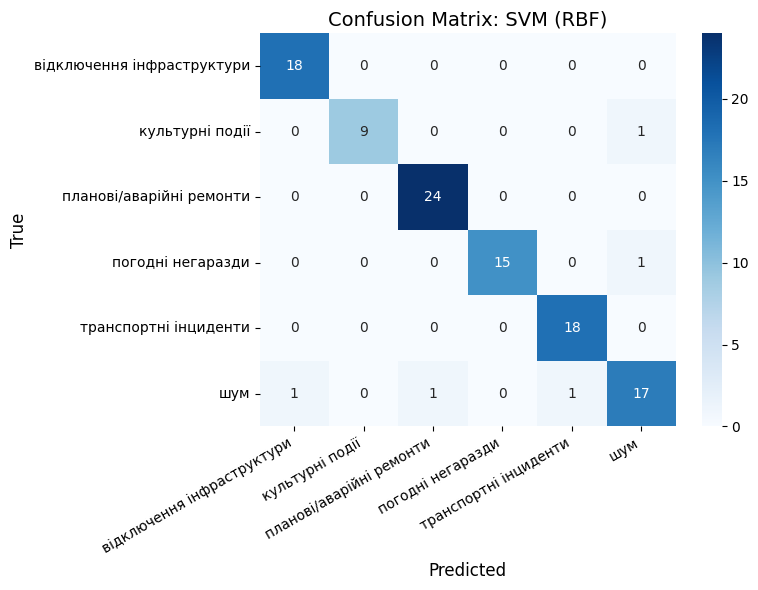

In [6]:
best_name = max(
    results,
    key=lambda n: float(classification_report(y_test, results[n]["y_pred"],
                        output_dict=True, zero_division=0)["macro avg"]["f1-score"]
    )
)

best_clf = results[best_name]["clf"]
classes = sorted(set(df['event_type']))
classes_ids = range(len(label_encoder.classes_))
cm = confusion_matrix(y_test, results[best_name]["y_pred"], labels=classes_ids)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=classes, yticklabels=classes, ax=ax
)
ax.set_xlabel("Predicted", fontsize=12)
ax.set_ylabel("True",   fontsize=12)
ax.set_title(f"Confusion Matrix: {best_name}", fontsize=14)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [8]:
demo_texts = [
    "Прорив труби на Оболоні, вода затопила підвали",
    "Пробка на Кільцевій через ДТП, стоїть 5 км",
    "Концерт гурту в парку Шевченка сьогодні ввечері 🎶",
    "Сильний туман в Бортничах, видимість 50 метрів",
    "Мітинг біля КМДА о 12:00",
    "Новий пішохідний міст побудують у парку на вулиці Прирічній в Оболонському районі, – про це повідомив заступник голови КМДА\nПарковий міст стане частиною оновлення південно-західної частини парку, а будівництво здійснюється за грантові кошти Литовської Республіки.\n✈️ якщо ви побачили щось цікаве, інформативне чи важливе – швиденько надсилайте нам, ми покажемо це на каналі — @novosti_kieva_bot",
    "В нашій області викрили екс-тероборонівця, який після звільнення почав підпільно продавати озброєння\nВласне, він розбирав засоби ураження на частини і потрохи відправляв їх замовникам поштою.\nЧоловік вказував їх як побутові речі, а після завершення «угоди» видаляв контакти замовника та змінював сім-карту.",
    "Uklon за рік сплатив понад 1 мільярд грн податків!\nЦе абсолютний рекорд для компанії та у 1,5 раза більше за показники 2024 року\nТакий результат став можливим завдяки стрімкому зростанню: річний дохід сервісу сягнув $101 млн, а кількість щомісячних активних користувачів — 3,8 млн 🚗",
    " У Києві на декілька днів тимчасово змінили звичні платформи для посадки та висадки пасажирів Київської кільцевої електрички\nТож, 19-21 березня 4 денних поїзди Дарниця – Вокзальна – Святошин прибуватимуть на станції Протасів Яр, Вокзальна та Караваєві Дачі на резервні платформи:",
    "Оновлення в графіку відключення електроенергії сьогодні для Київщини\nЗавчасно про зміни попередять тут – kyiv_svitlo",
    ]

print("Predictions for demo texts:")
demo_emb = model.encode(demo_texts)
demo_pred = best_clf.predict(demo_emb)

for text, pred in zip(demo_texts, demo_pred):
    name = label_encoder.classes_[pred]
    print(f"[{name}]  {text:.80}")

Predictions for demo texts:
[відключення інфраструктури]  Прорив труби на Оболоні, вода затопила підвали
[транспортні інциденти]  Пробка на Кільцевій через ДТП, стоїть 5 км
[культурні події]  Концерт гурту в парку Шевченка сьогодні ввечері 🎶
[погодні негаразди]  Сильний туман в Бортничах, видимість 50 метрів
[шум]  Мітинг біля КМДА о 12:00
[шум]  Новий пішохідний міст побудують у парку на вулиці Прирічній в Оболонському район
[шум]  В нашій області викрили екс-тероборонівця, який після звільнення почав підпільно
[шум]  Uklon за рік сплатив понад 1 мільярд грн податків!
Це абсолютний рекорд для комп
[планові/аварійні ремонти]   У Києві на декілька днів тимчасово змінили звичні платформи для посадки та виса
[відключення інфраструктури]  Оновлення в графіку відключення електроенергії сьогодні для Київщини
Завчасно пр


# filter noise

In [9]:
texts = df[df['event_type'] != 'шум']['text'].tolist()
labels = df[df['event_type'] != 'шум']['is_actionable'].tolist()

print(f"is_actionable=True: {sum(labels)}")
print(f"is_actionable=False: {sum(1 for l in labels if not l)}")

y = np.array([1 if l else 0 for l in labels])

is_actionable=True: 411
is_actionable=False: 17


In [10]:
r = df[(df['event_type'] != 'шум') & (df['is_actionable'] == False)]['text'].tolist()
r

['🌧️ Потужна злива очікується у Києві після 15:00 — синоптики попереджають про підтоплення.',
 'КП «Київводоканал» інформує про план проведення комплексного ремонту водопровідної мережі у Деснянському районі у червні-серпні 2024 року. За підсумками попереднього кварталу замінено понад 12 км труб. Роботи тривають відповідно до затвердженого графіка.',
 "КК «Київавтодор» повідомляє, що за травень 2024 року у Солом'янському районі відремонтовано понад 45 км доріг та замінено 1200 пог. м бордюрного каменю. Роботи тривають відповідно до затвердженого плану розвитку дорожньо-транспортної інфраструктури міста.",
 'КМДА повідомляє, що за результатами аналізу аварійності на дорогах Києва у травні 2024 року кількість ДТП зменшилася на 12% порівняно з аналогічним періодом 2023 року. Патрульна поліція та КМДА продовжують роботу щодо підвищення безпеки дорожнього руху.',
 "Повідомляємо, що 18 травня 2024 року у Києві оголошено штормове попередження у зв'язку з очікуванням сильного вітру зі швидкіст

## 1. binary classifier

In [11]:
texts = df[df['event_type'] != 'шум']['text'].tolist()
labels = df[df['event_type'] != 'шум']['is_actionable'].tolist()

print(f"is_actionable=True: {sum(labels)}")
print(f"is_actionable=False: {sum(1 for l in labels if not l)}")

y = np.array([1 if l else 0 for l in labels])

is_actionable=True: 411
is_actionable=False: 17


In [16]:
X = model.encode(texts, show_progress_bar=True, batch_size=32)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=12, stratify=y)

classifiers = {
    "LogReg":    LogisticRegression(max_iter=1000, C=5, random_state=42),
    "SVM (RBF)": SVC(kernel="rbf", C=5, gamma="scale", probability=True, random_state=42),
    "SVM (Linear)": SVC(kernel="linear", C=5, gamma="scale", probability=True, random_state=42),
}

results = {}
for name, clf in classifiers.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]
    results[name] = {"clf": clf, "y_pred": y_pred, "y_prob": y_prob}
    print(f"\n{name}")
    print(classification_report(y_test, y_pred, target_names=["noise (False)", "event (True)"], zero_division=0))


Batches: 100%|██████████| 14/14 [00:45<00:00,  3.26s/it]


LogReg
               precision    recall  f1-score   support

noise (False)       1.00      1.00      1.00         3
 event (True)       1.00      1.00      1.00        83

     accuracy                           1.00        86
    macro avg       1.00      1.00      1.00        86
 weighted avg       1.00      1.00      1.00        86


SVM (RBF)
               precision    recall  f1-score   support

noise (False)       1.00      1.00      1.00         3
 event (True)       1.00      1.00      1.00        83

     accuracy                           1.00        86
    macro avg       1.00      1.00      1.00        86
 weighted avg       1.00      1.00      1.00        86


SVM (Linear)
               precision    recall  f1-score   support

noise (False)       1.00      1.00      1.00         3
 event (True)       1.00      1.00      1.00        83

     accuracy                           1.00        86
    macro avg       1.00      1.00      1.00        86
 weighted avg       1.00

## 2. rule-based

In [17]:
NOISE_PATTERNS = [
    r"читайте\s+тут",
    r"дізнайтесь\s+(тут|за посиланням|більше)",
    r"детальніше\s*(→|тут|за посиланням|:)",
    r"більше\s+інформації",
    r"повний\s+список",
    r"(?<!\S)https?://\S+\s*$",
    r"за\s+(цей|минулий|перший|другий|третій|четвертий)\s+(рік|квартал|місяць)",
    r"з\s+початку\s+року",
    r"(?:км|кілометр)\s+доріг",
    r"тендер",
    r"план\s+розвитку",
    r"до\s+20\d\d\s+року",
    r"топ-\d+",
    r"рейтинг",
    r"опитування",
    r"відбій\s+повітряної\s+тривоги",
    r"повітряна\s+тривога\s+відбій",
    r"тривога\s+відбій",
    r"тривога"
    r"детальніше",
    r"дізнайтесь?",
    r"читайте тут",
    r"читай тут",
    r"посилання",
    r"в коментарях",
    r"нижче в пості",
    r"вся інформація",
    r"за\s+(цей|минулий|перший|другий|третій|четвертий)\s+(рік|квартал|місяць)",
    r"з\s+початку\s+року",
    r"\d+\s*(км|кілометр)",
    r"план\s+розвитку",
    r"до\s+20\d\d\s+року",
    r"статистика",
    r"підсумки",
    r"топ-\d+",
    r"рейтинг",
    r"опитування",
    r"голосування",
    r"відбій тривоги",
    r"відбій повітряної",
    r"акція",
    r"знижка",
    r"донат",
    r"допоможіть",
    r"збір",
    r"волонтери",
    r"за\s+(травень|червень|липень|серпень|вересень|жовтень|листопад|грудень|січень|лютий|березень|квітень)",
    r"за\s+(результатами|підсумками|аналізу|даними)",
    r"зменшил(?:ася|ося|ись)",
    r"збільшил(?:ася|ося|ись)",
    r"порівняно з",
    r"відремонтовано",
    r"замінено",
    r"виконано",
    r"проведено",
    r"за\s+\d+\s+місяць",
    r"за\s+попередній\s+квартал",
    r"за\s+цей\s+рік",
    r"план\s+проведення",
    r"у\s+(червні|липні|серпні|вересні|жовтні|листопаді|грудні)",
    r"комплексного\s+ремонту",
    r"очікується",
    r"сильний дощ",
    r"сильний вітер",
    r"рекомендує мешканцям",
    r"режим підвищеної готовності",
    r"продовжують роботу щодо",
]

NOISE_RE = re.compile(
    "|".join(NOISE_PATTERNS),
    flags=re.IGNORECASE | re.UNICODE
)

def rule_based_filter(text: str) -> bool:
    if NOISE_RE.search(text):
        return False
    return True

y_pred_rules = np.array([1 if rule_based_filter(t) else 0 for t in texts])
print(classification_report(y, y_pred_rules, target_names=["noise (False)", "event (True)"], zero_division=0))

               precision    recall  f1-score   support

noise (False)       0.67      0.82      0.74        17
 event (True)       0.99      0.98      0.99       411

     accuracy                           0.98       428
    macro avg       0.83      0.90      0.86       428
 weighted avg       0.98      0.98      0.98       428



## 3. rule-based + ml

In [18]:
CONFIDENCE_THRESHOLD = 0.4  

best_name = max(results, key=lambda n: float(classification_report(y_test, results[n]["y_pred"],
                  output_dict=True, zero_division=0)["1"]["f1-score"]))
best_clf = results[best_name]["clf"]

def combined_filter(text: str, embedding: np.ndarray) -> tuple[bool, str]:
    if not rule_based_filter(text):
        return False, "rule_based"

    prob = best_clf.predict_proba(embedding.reshape(1, -1))[0][1]
    if prob < CONFIDENCE_THRESHOLD:
        return False, f"ml_low_confidence ({prob:.2f})"

    return True, f"passed ({prob:.2f})"

texts_test  = [texts[i] for i in range(len(texts)) if i >= int(len(texts) * 0.8)] 
X_test_emb = X[int(len(texts) * 0.8):]
y_test_combined = y[int(len(texts) * 0.8):]

y_pred_combined = []
reasons = []
for text, emb in zip(texts_test, X_test_emb):
    result, reason = combined_filter(text, emb)
    y_pred_combined.append(1 if result else 0)
    reasons.append(reason)

y_pred_combined = np.array(y_pred_combined)

print(classification_report(y_test_combined, y_pred_combined, target_names=["noise (False)", "event (True)"], zero_division=0))

rejected = [r for r, p in zip(reasons, y_pred_combined) if p == 0]
print(f"\nReasons for rejection ({len(rejected)} examples):")
for reason, cnt in Counter(rejected).most_common():
    print(f"  {reason:<35} {cnt}")

               precision    recall  f1-score   support

noise (False)       0.80      0.80      0.80         5
 event (True)       0.99      0.99      0.99        81

     accuracy                           0.98        86
    macro avg       0.89      0.89      0.89        86
 weighted avg       0.98      0.98      0.98        86


Reasons for rejection (5 examples):
  rule_based                          5


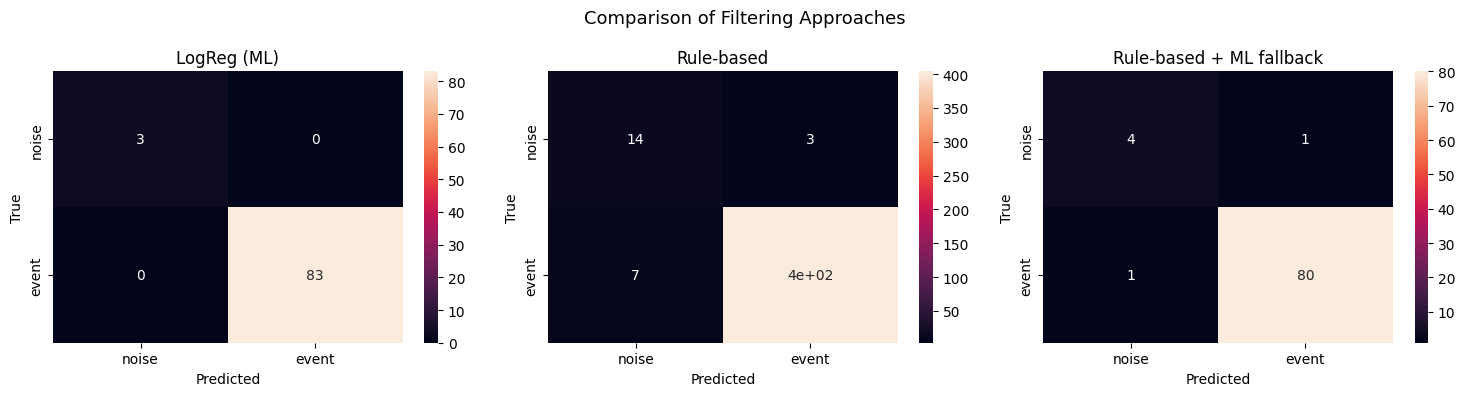

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
labels_cm = ["noise", "event"]

cm_A = confusion_matrix(y_test, results[best_name]["y_pred"])
sns.heatmap(cm_A, annot=True, xticklabels=labels_cm, yticklabels=labels_cm, ax=axes[0])
axes[0].set_title(f"{best_name} (ML)")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")

cm_B = confusion_matrix(y, y_pred_rules)
sns.heatmap(cm_B, annot=True, xticklabels=labels_cm, yticklabels=labels_cm, ax=axes[1])
axes[1].set_title("Rule-based")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True")

cm_C = confusion_matrix(y_test_combined, y_pred_combined)
sns.heatmap(cm_C, annot=True, xticklabels=labels_cm, yticklabels=labels_cm, ax=axes[2])
axes[2].set_title("Rule-based + ML fallback")
axes[2].set_xlabel("Predicted"); axes[2].set_ylabel("True")

plt.suptitle("Comparison of Filtering Approaches", fontsize=13)
plt.tight_layout()
plt.show()

In [21]:
demo = [
    # True
    "🚧 Аварійний ремонт водопроводу на вул. Оболонська 15, воду відключено до 20:00",
    "ДТП на перехресті просп. Перемоги і вул. Дорогожицька, рух ускладнено",
    "Повідомляємо про обмеження руху на вул. Хрещатик з 10:00 до 22:00 у зв'язку з проведенням заходу",

    # False
    "Оновлення в графіку відключення електроенергії сьогодні для Київщини\nДізнайтесь тут – kyiv_svitlo 👉",
    "ТОП-5 найбільших заторів цього тижня 📊 Читайте у нашому матеріалі",
    "За підсумками першого кварталу відремонтовано 234 км доріг. Роботи тривають відповідно до плану.",
    "🟢ВІДБІЙ ПОВІТРЯНОЇ ТРИВОГИ🟢",
]

demo_emb = model.encode(demo)
for text, emb in zip(demo, demo_emb):
    result, reason = combined_filter(text, emb)
    short = text[:80].replace("\n", " ")
    print(f"[{result}, {reason}]  {short}")

[True, passed (1.00)]  🚧 Аварійний ремонт водопроводу на вул. Оболонська 15, воду відключено до 20:00
[True, passed (1.00)]  ДТП на перехресті просп. Перемоги і вул. Дорогожицька, рух ускладнено
[True, passed (1.00)]  Повідомляємо про обмеження руху на вул. Хрещатик з 10:00 до 22:00 у зв'язку з пр
[False, rule_based]  Оновлення в графіку відключення електроенергії сьогодні для Київщини Дізнайтесь 
[False, rule_based]  ТОП-5 найбільших заторів цього тижня 📊 Читайте у нашому матеріалі
[False, rule_based]  За підсумками першого кварталу відремонтовано 234 км доріг. Роботи тривають відп
[False, rule_based]  🟢ВІДБІЙ ПОВІТРЯНОЇ ТРИВОГИ🟢
